# Controlled RevIN ablation: ModernTCN only

This pilot compares exactly two configurations of the existing ModernTCN implementation: RevIN OFF and RevIN ON. All non-RevIN model settings, data, sampled windows, initialization seed, minibatch order, optimizer, validation rule, and test set are held fixed.

The project pipeline first applies its train-fitted standard scaler to the ETT splits. With RevIN ON, the model then computes per-window input statistics and denormalizes its output back into that same globally standardized space. With RevIN OFF, the model bypasses RevIN entirely. The test set is evaluated once per selected checkpoint.

## Execution outline

1. Detect dependencies, runtime, device, repository, and optional Drive mount.
2. Reuse the project's ETTh1 splits, train-only scaler, and existing 5% seeded training-window sample.
3. Verify the existing RevIN path and confirm identical initial shared weights.
4. Run one pilot training/validation step per configuration.
5. Train both configurations sequentially with fresh models and optimizers.
6. Select checkpoints on validation MSE and evaluate each checkpoint once on the held-out test set.
7. Save a two-row comparison, metric improvements, plots, logs, checkpoints, configuration, and report.

## 1. Runtime, dependencies, repository access, and device

In [1]:
from pathlib import Path
import os, sys, json, time, random, contextlib, io, subprocess, importlib.util
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

required_modules = ["numpy", "pandas", "yaml", "matplotlib", "torch"]
missing_modules = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing_modules:
    raise ImportError(f"Missing required packages: {missing_modules}. Install the project's requirements before continuing.")

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ
print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__)
print("Colab runtime:", IN_COLAB)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    DEVICE = torch.device("cuda:0")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("GPU: unavailable; using CPU")
print("Selected device:", DEVICE)

# Set this if the repo checkout is in a non-standard location.
REPO_ROOT_OVERRIDE = None
repo_candidates = [Path(REPO_ROOT_OVERRIDE)] if REPO_ROOT_OVERRIDE else []
repo_candidates.extend([Path.cwd(), Path("/content/ModernTCN"), Path("/content/drive/MyDrive/ModernTCN")])
REPO_ROOT = next((p.resolve() for p in repo_candidates if p and (p / "src/models/moderntcn.py").is_file()), None)
if REPO_ROOT is None and IN_COLAB:
    repo_url = "https://github.com/Basmala-ElKady/ModernTCN.git"
    subprocess.run(["git", "clone", "--depth", "1", repo_url, "/content/ModernTCN"], check=True)
    REPO_ROOT = Path("/content/ModernTCN").resolve()
if REPO_ROOT is None:
    raise FileNotFoundError("ModernTCN repository not found. Set REPO_ROOT_OVERRIDE to the repository checkout.")
os.chdir(REPO_ROOT)
print("Repository:", REPO_ROOT)

import yaml
from src.data.dataset import build_datasets, WindowDataset
from src.data.preprocessing import get_split_borders
from src.models.moderntcn import build_moderntcn
from src.training.train import train_model
from src.training.evaluate import evaluate_model
from src.utils.checkpoint import load_checkpoint
from src.utils.seed import set_seed
from torch.utils.data import DataLoader, Subset
print("Using existing preprocessing, ModernTCN, training, evaluation, checkpoint, and seed utilities.")

Python: 3.12.5 | PyTorch: 2.11.0+cpu
Colab runtime: False
CUDA available: False
GPU: unavailable; using CPU
Selected device: cpu
Repository: D:\University Materials\year 4\Deep Learning\ModernTCN
Using existing preprocessing, ModernTCN, training, evaluation, checkpoint, and seed utilities.


## 2. Fixed pilot configuration and output directory

In [2]:
with open(REPO_ROOT / "configs/default.yaml", encoding="utf-8") as f:
    PROJECT_CONFIG = yaml.safe_load(f)

SEED = 42
DATASET = "ETTh1"
DATA_DIR = REPO_ROOT / "Datasets"
SEQ_LEN = int(PROJECT_CONFIG["data"]["input_length"])
PRED_LEN = int(PROJECT_CONFIG["data"]["forecast_horizons"][0])
TRAIN_SAMPLE_FRACTION = 0.05
BATCH_SIZE = int(PROJECT_CONFIG["training"]["batch_size"])
LEARNING_RATE = float(PROJECT_CONFIG["training"]["learning_rate"])
EPOCHS = 2  # existing sample pilot setting
PATIENCE = min(int(PROJECT_CONFIG["training"]["patience"]), EPOCHS)
NUM_WORKERS = 0

# Explicitly freeze all existing ModernTCN defaults; only use_revin will vary.
MODERNTCN_HPARAMS = {
    "embed_dim": 64, "depth": 3, "kernel_size": 31,
    "small_kernel_size": 5, "patch_size": 16, "patch_stride": 8,
    "ffn_ratio": 2.0, "dropout": 0.1, "revin_affine": True,
}
MOUNT_GOOGLE_DRIVE = False  # Set True in Colab to mount Drive interactively.
if IN_COLAB and MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive")
if drive_root.is_dir():
    OUTPUT_BASE = drive_root / "ModernTCN_sample_comparison"
elif Path("/content").is_dir():
    OUTPUT_BASE = Path("/content/ModernTCN_sample_comparison")
else:
    OUTPUT_BASE = REPO_ROOT / "colab_sample_outputs"
RUN_ID = time.strftime("%Y%m%d_%H%M%S") + f"_{time.time_ns() % 1_000_000:06d}_moderntcn_revin_ablation"
OUTPUT_DIR = OUTPUT_BASE / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
(OUTPUT_DIR / "checkpoints").mkdir()
(OUTPUT_DIR / "logs").mkdir()
(OUTPUT_DIR / "plots").mkdir()

BASE_TRAIN_CONFIG = {
    "dataset": DATASET, "data_dir": str(DATA_DIR), "input_length": SEQ_LEN,
    "forecast_horizon": PRED_LEN, "num_variables": 7, "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE, "epochs": EPOCHS, "patience": PATIENCE,
    "device": str(DEVICE), "seed": SEED,
}
CONFIG = {
    **BASE_TRAIN_CONFIG, "features": "M",
    "train_sample_fraction": TRAIN_SAMPLE_FRACTION,
    "model": "ModernTCN", "moderntcn_shared_hyperparameters": MODERNTCN_HPARAMS,
    "revin_affine": True, "revin_subtract_last": False,
    "metric_space": "globally standardized values",
    "checkpoint_selection": "lowest validation MSE",
    "test_evaluations_per_configuration": 1,
    "runtime": "Google Colab" if IN_COLAB else "local/non-Colab",
    "device_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "output_dir": str(OUTPUT_DIR),
}
(OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print(json.dumps(CONFIG, indent=2))

{
  "dataset": "ETTh1",
  "data_dir": "D:\\University Materials\\year 4\\Deep Learning\\ModernTCN\\Datasets",
  "input_length": 336,
  "forecast_horizon": 96,
  "num_variables": 7,
  "batch_size": 32,
  "learning_rate": 0.001,
  "epochs": 2,
  "patience": 2,
  "device": "cpu",
  "seed": 42,
  "features": "M",
  "train_sample_fraction": 0.05,
  "model": "ModernTCN",
  "moderntcn_shared_hyperparameters": {
    "embed_dim": 64,
    "depth": 3,
    "kernel_size": 31,
    "small_kernel_size": 5,
    "patch_size": 16,
    "patch_stride": 8,
    "ffn_ratio": 2.0,
    "dropout": 0.1,
    "revin_affine": true
  },
  "revin_affine": true,
  "revin_subtract_last": false,
  "metric_space": "globally standardized values",
  "checkpoint_selection": "lowest validation MSE",
  "test_evaluations_per_configuration": 1,
  "runtime": "local/non-Colab",
  "device_name": "CPU",
  "output_dir": "D:\\University Materials\\year 4\\Deep Learning\\ModernTCN\\colab_sample_outputs\\20261026_173207_978500_moderntcn

## 3. Reuse dataset loader, preprocessing, splits, and exact seeded sample

In [3]:
csv_path = DATA_DIR / f"{DATASET}.csv"
if not csv_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {csv_path}")
raw_df = pd.read_csv(csv_path)
print("Raw shape:", raw_df.shape, "| columns:", raw_df.columns.tolist())
print("Time range:", raw_df.iloc[0, 0], "to", raw_df.iloc[-1, 0])
display(raw_df.head())

# This calls the repository's ETTh1 12/4/4 chronological split and train-only scaler.
sets, scaler = build_datasets(str(csv_path), DATASET, SEQ_LEN, PRED_LEN)
split_borders = get_split_borders(DATASET, SEQ_LEN)
full_window_counts = {name: len(dataset) for name, dataset in sets.items()}
n_train = full_window_counts["train"]
n_sample = max(1, int(round(n_train * TRAIN_SAMPLE_FRACTION)))
sample_rng = np.random.default_rng(SEED)
sample_indices = np.sort(sample_rng.choice(n_train, size=n_sample, replace=False)).astype(int).tolist()
train_subset = Subset(sets["train"], sample_indices)

# Identical ordered sample and split objects feed both configurations.
loaders = {
    "val": DataLoader(sets["val"], batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
    "test": DataLoader(sets["test"], batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
}
timestamp_col = pd.to_datetime(raw_df.iloc[:, 0])
target_start = SEQ_LEN + sample_indices[0]
target_end = SEQ_LEN + sample_indices[-1] + PRED_LEN - 1
sampling_metadata = {
    "dataset": DATASET, "csv_path": str(csv_path), "raw_rows": len(raw_df),
    "feature_columns": raw_df.columns[1:].tolist(), "features_mode": "M",
    "seq_len": SEQ_LEN, "pred_len": PRED_LEN,
    "split_row_borders": {k: list(v) for k, v in split_borders.items()},
    "window_counts": full_window_counts, "sample_seed": SEED,
    "train_windows_sampled": n_sample, "train_windows_total": n_train,
    "actual_sample_fraction": n_sample / n_train,
    "sampled_indices_sorted": sample_indices,
    "sampled_target_time_range": [str(timestamp_col.iloc[target_start]), str(timestamp_col.iloc[target_end])],
    "scaler_fit_rows": list(split_borders["train"]),
    "scaler_mean": scaler.mean.tolist(), "scaler_std": scaler.std.tolist(),
}
(OUTPUT_DIR / "sampling_metadata.json").write_text(json.dumps(sampling_metadata, indent=2), encoding="utf-8")
print("Window counts:", full_window_counts, "| selected training windows:", n_sample)
print("Sample target time range:", sampling_metadata["sampled_target_time_range"])
print("Scaler was fitted only on train rows:", sampling_metadata["scaler_fit_rows"])
print("RevIN is model-local per input window; it does not fit on validation/test data.")

Raw shape: (17420, 8) | columns: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Time range: 2016-07-01 00:00:00 to 2018-06-26 19:00:00
                  date   HUFL   HULL   MUFL   MULL   LUFL   LULL         OT
0  2016-07-01 00:00:00  5.827  2.009  1.599  0.462  4.203  1.340  30.531000
1  2016-07-01 01:00:00  5.693  2.076  1.492  0.426  4.142  1.371  27.787001
2  2016-07-01 02:00:00  5.157  1.741  1.279  0.355  3.777  1.218  27.787001
3  2016-07-01 03:00:00  5.090  1.942  1.279  0.391  3.807  1.279  25.044001
4  2016-07-01 04:00:00  5.358  1.942  1.492  0.462  3.868  1.279  21.948000
Window counts: {'train': 8209, 'val': 2785, 'test': 2785} | selected training windows: 410
Sample target time range: ['2016-07-16 19:00:00', '2017-06-24 23:00:00']
Scaler was fitted only on train rows: [0, 8640]
RevIN is model-local per input window; it does not fit on validation/test data.


## 4. Audit RevIN path and freeze the controlled model configurations

In [4]:
def make_config(use_revin):
    return {
        **BASE_TRAIN_CONFIG,
        "model_name": "moderntcn",
        "moderntcn": {**MODERNTCN_HPARAMS, "use_revin": bool(use_revin)},
    }

CONFIGS = {"OFF": make_config(False), "ON": make_config(True)}
config_off_comparable = json.loads(json.dumps(CONFIGS["OFF"]))
config_off_comparable["moderntcn"]["use_revin"] = True
assert config_off_comparable == CONFIGS["ON"], "RevIN must be the only configuration difference."

set_seed(SEED)
model_off_check = build_moderntcn(CONFIGS["OFF"])
assert model_off_check.revin is None and model_off_check.use_revin is False
set_seed(SEED)
model_on_check = build_moderntcn(CONFIGS["ON"])
assert model_on_check.revin is not None and model_on_check.use_revin is True
shared_keys = [k for k in model_off_check.state_dict() if k in model_on_check.state_dict()]
assert shared_keys and all(torch.equal(model_off_check.state_dict()[k], model_on_check.state_dict()[k]) for k in shared_keys), "Shared weights should initialize identically under the same seed."
assert all(k.startswith("revin.") for k in set(model_on_check.state_dict()) - set(model_off_check.state_dict()))

# Verify the actual input-window statistics and reversible affine transform.
pilot_x, _ = next(iter(DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=False)))
pilot_x = pilot_x.to(DEVICE)
roundtrip = model_on_check.revin.denormalize(model_on_check.revin.normalize(pilot_x))
assert torch.allclose(roundtrip, pilot_x, atol=2e-5, rtol=2e-5)
rev_calls = {"normalize": 0, "denormalize": 0}
_original_normalize = model_on_check.revin.normalize
_original_denormalize = model_on_check.revin.denormalize
def _counted_normalize(value):
    rev_calls["normalize"] += 1
    return _original_normalize(value)
def _counted_denormalize(value):
    rev_calls["denormalize"] += 1
    return _original_denormalize(value)
model_on_check.revin.normalize = _counted_normalize
model_on_check.revin.denormalize = _counted_denormalize
with torch.no_grad():
    _ = model_off_check(pilot_x)
    _ = model_on_check(pilot_x)
assert rev_calls == {"normalize": 1, "denormalize": 1}, rev_calls
expected_mean = pilot_x.mean(dim=1, keepdim=True)
expected_std = pilot_x.var(dim=1, keepdim=True, unbiased=False).add(model_on_check.revin.eps).sqrt()
assert torch.allclose(model_on_check.revin._mean, expected_mean)
assert torch.allclose(model_on_check.revin._stdev, expected_std)
print("RevIN OFF: revin=None; normalization/denormalization bypassed.")
print("RevIN ON: per-window input mean/std verified; normalize-denormalize round trip passed.")
print("Verified actual forward() calls normalize() and denormalize() once; OFF bypasses both.")
print("Only config difference: moderntcn.use_revin; shared initial parameter tensors:", len(shared_keys))
del model_off_check, model_on_check

RevIN OFF: revin=None; normalization/denormalization bypassed.
RevIN ON: per-window input mean/std verified; normalize-denormalize round trip passed.
Verified actual forward() calls normalize() and denormalize() once; OFF bypasses both.
Only config difference: moderntcn.use_revin; shared initial parameter tensors: 42


## 5. Pilot training and validation step for both settings

In [5]:
pilot_results = {}
for label in ("OFF", "ON"):
    set_seed(SEED)
    model = build_moderntcn(CONFIGS[label]).to(DEVICE)
    train_generator = torch.Generator().manual_seed(SEED)
    pilot_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator)
    x, y = next(iter(pilot_loader))
    x, y = x.to(DEVICE, dtype=torch.float32), y.to(DEVICE, dtype=torch.float32)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    model.train()
    optimizer.zero_grad(set_to_none=True)
    pred = model(x)
    assert pred.shape == y.shape, f"{label}: {tuple(pred.shape)} != {tuple(y.shape)}"
    loss = torch.mean((pred - y) ** 2)
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.no_grad():
        val_x, val_y = next(iter(loaders["val"]))
        val_pred = model(val_x.to(DEVICE, dtype=torch.float32))
        val_loss = torch.mean((val_pred - val_y.to(DEVICE, dtype=torch.float32)) ** 2)
    pilot_results[label] = {
        "ok": True, "device": str(next(model.parameters()).device),
        "revin_flag": model.use_revin, "train_step_mse": float(loss.detach().cpu()),
        "validation_batch_mse": float(val_loss.detach().cpu()),
        "input_shape": list(x.shape), "forecast_shape": list(pred.shape),
    }
    print(label, pilot_results[label])
    del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
(OUTPUT_DIR / "pilot_results.json").write_text(json.dumps(pilot_results, indent=2), encoding="utf-8")

OFF {'ok': True, 'device': 'cpu', 'revin_flag': False, 'train_step_mse': 1.15146803855896, 'validation_batch_mse': 1.422846794128418, 'input_shape': [32, 336, 7], 'forecast_shape': [32, 96, 7]}
ON {'ok': True, 'device': 'cpu', 'revin_flag': True, 'train_step_mse': 0.7550206184387207, 'validation_batch_mse': 0.702320396900177, 'input_shape': [32, 336, 7], 'forecast_shape': [32, 96, 7]}


## 6. Train sequentially, select by validation MSE, test each best checkpoint once

In [6]:
required_columns = [
    "model", "revin", "status", "best_epoch", "best_val_mse", "test_mse",
    "test_mae", "test_rmse", "training_time_seconds", "test_inference_time_seconds",
    "peak_gpu_memory_mb", "device", "checkpoint", "parameters",
]
rows, histories, run_errors = [], {}, {}
for label in ("OFF", "ON"):
    cfg = CONFIGS[label]
    checkpoint_path = OUTPUT_DIR / "checkpoints" / f"moderntcn_revin_{label.lower()}_best.pt"
    run_log = io.StringIO()
    result = {
        "model": "ModernTCN", "revin": label, "status": "failed",
        "best_epoch": None, "best_val_mse": None, "test_mse": None, "test_mae": None,
        "test_rmse": None, "training_time_seconds": None, "test_inference_time_seconds": None,
        "peak_gpu_memory_mb": None, "device": str(DEVICE), "checkpoint": str(checkpoint_path),
        "parameters": None,
    }
    try:
        set_seed(SEED)
        # Fresh model and fresh DataLoader shuffle generator for each paired run.
        model = build_moderntcn(cfg).to(DEVICE)
        assert model.use_revin is (label == "ON")
        train_generator = torch.Generator().manual_seed(SEED)
        train_loader = DataLoader(
            train_subset, batch_size=BATCH_SIZE, shuffle=True,
            generator=train_generator, num_workers=NUM_WORKERS,
        )
        result["parameters"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats(DEVICE)
        start_train = time.perf_counter()
        with contextlib.redirect_stdout(run_log):
            train_result = train_model(model, train_loader, loaders["val"], cfg, checkpoint_path)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        result["training_time_seconds"] = time.perf_counter() - start_train
        result["best_epoch"] = int(train_result["best_epoch"])
        result["best_val_mse"] = float(train_result["best_val_mse"])
        histories[label] = train_result["history"]

        # Verify the saved checkpoint belongs to this RevIN setting before restoring it.
        saved = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
        saved_flag = bool(saved["config"]["moderntcn"]["use_revin"])
        assert saved_flag is (label == "ON"), f"Checkpoint RevIN flag mismatch for {label}"
        assert int(saved["epoch"]) == result["best_epoch"]
        load_checkpoint(checkpoint_path, model, device=str(DEVICE))
        assert model.use_revin is (label == "ON")

        # Final test-set evaluation occurs exactly once per selected checkpoint.
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        start_inference = time.perf_counter()
        test_metrics = evaluate_model(model, loaders["test"], DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        result["test_inference_time_seconds"] = time.perf_counter() - start_inference
        result.update({
            "status": "ok", "test_mse": float(test_metrics["mse"]),
            "test_mae": float(test_metrics["mae"]),
            "test_rmse": float(np.sqrt(test_metrics["mse"])),
        })
        if DEVICE.type == "cuda":
            result["peak_gpu_memory_mb"] = torch.cuda.max_memory_allocated(DEVICE) / (1024**2)
        assert all(np.isfinite(result[k]) for k in ["best_val_mse", "test_mse", "test_mae", "test_rmse"])
        print(label, result)
    except Exception as exc:
        run_errors[label] = repr(exc)
        run_log.write("\nERROR: " + repr(exc))
        print(label, "FAILED:", repr(exc))
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    finally:
        (OUTPUT_DIR / "logs" / f"revin_{label.lower()}.log").write_text(run_log.getvalue(), encoding="utf-8")
        rows.append(result)
        if "model" in locals():
            del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

results_df = pd.DataFrame(rows, columns=required_columns)
assert len(results_df) == 2 and results_df["revin"].tolist() == ["OFF", "ON"]
display(results_df)
(OUTPUT_DIR / "training_histories.json").write_text(json.dumps(histories, indent=2), encoding="utf-8")
results_df.to_csv(OUTPUT_DIR / "results.csv", index=False)


OFF {'model': 'ModernTCN', 'revin': 'OFF', 'status': 'ok', 'best_epoch': 2, 'best_val_mse': 1.0607041651401354, 'test_mse': 0.6455558762342857, 'test_mae': 0.5605044838545862, 'test_rmse': 0.8034649191061709, 'training_time_seconds': 5.147763599990867, 'test_inference_time_seconds': 0.8888641999801621, 'peak_gpu_memory_mb': None, 'device': 'cpu', 'checkpoint': 'D:\\University Materials\\year 4\\Deep Learning\\ModernTCN\\colab_sample_outputs\\20261026_173207_978500_moderntcn_revin_ablation\\checkpoints\\moderntcn_revin_off_best.pt', 'parameters': 65248}
ON {'model': 'ModernTCN', 'revin': 'ON', 'status': 'ok', 'best_epoch': 2, 'best_val_mse': 0.9120561946566578, 'test_mse': 0.5045541162418282, 'test_mae': 0.47414170417090995, 'test_rmse': 0.7103197281800838, 'training_time_seconds': 5.610333700024057, 'test_inference_time_seconds': 1.0714268000156153, 'peak_gpu_memory_mb': None, 'device': 'cpu', 'checkpoint': 'D:\\University Materials\\year 4\\Deep Learning\\ModernTCN\\colab_sample_outpu

model,revin,status,best_epoch,best_val_mse,test_mse,test_mae,test_rmse,training_time_seconds,test_inference_time_seconds,peak_gpu_memory_mb,device,checkpoint,parameters
ModernTCN,OFF,ok,2,1.060704,0.645556,0.560504,0.803465,5.147764,0.888864,NaN,cpu,D:\University Materials\year 4\Deep Learning\ModernTCN\colab_sample_outputs\20261026_173207_978500_moderntcn_revin_ablation\checkpoints\moderntcn_revin_off_best.pt,65248
ModernTCN,ON,ok,2,0.912056,0.504554,0.474142,0.710320,5.610334,1.071427,NaN,cpu,D:\University Materials\year 4\Deep Learning\ModernTCN\colab_sample_outputs\20261026_173207_978500_moderntcn_revin_ablation\checkpoints\moderntcn_revin_on_best.pt,65262


## 7. Metric comparison, percentage change, and saved report

<notebook cell 7>:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
# ModernTCN RevIN ablation pilot

- Dataset: ETTh1; ETTh1 feature mode M; input 336; horizon 96.
- Preprocessing: existing chronological ETT 12/4/4 split; project standard scaler fitted on train rows only.
- Training sample: 410/8209 windows (4.99%), seed 42; same sorted indices for both settings.
- Training: batch size 32, Adam at 0.001, 2 maximum epochs, patience 2; best checkpoint selected using validation MSE.
- RevIN: existing per-window input mean/std, detached statistics, affine=True, eps=1e-5; output is inverse-normalized by the same window statistics. OFF sets model.revin=None. Global train-fitted standardization remains unchanged for both.
- Only intentional config difference: moderntcn.use_revin. Both runs use fresh model/optimizer, same initial shared weights, seed, shuffled minibatch order, validation and test windows.
- Runtime/device: local/non-Colab / cpu; GPU memory: not app

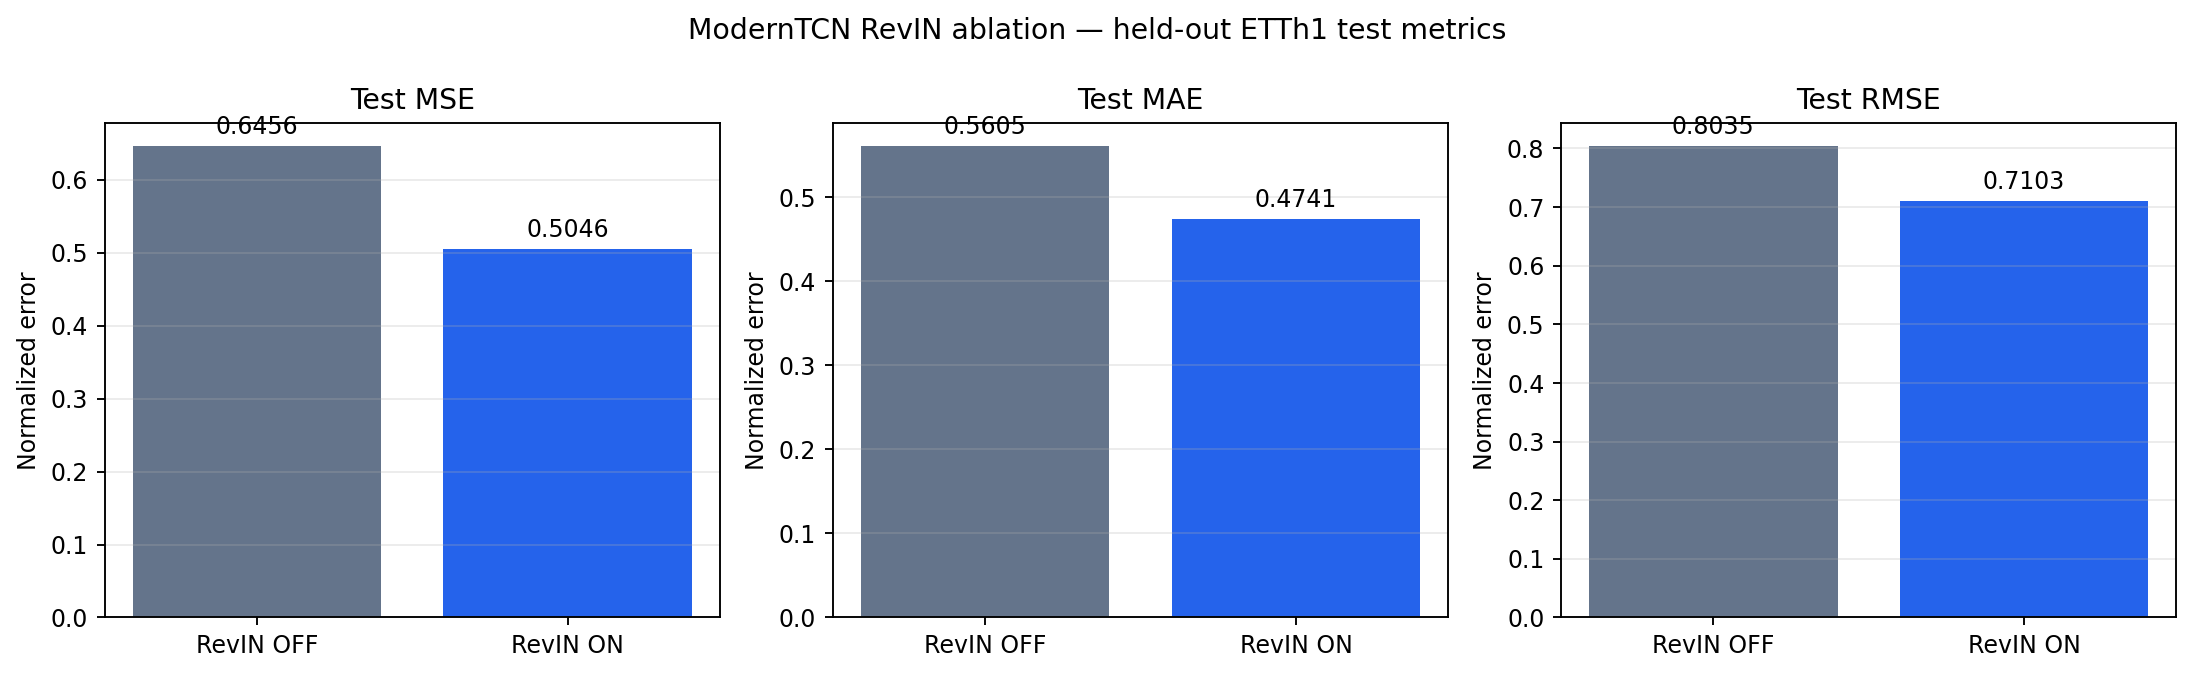

In [7]:
def improvement_percent(metric_off, metric_on):
    if metric_off is None or metric_on is None or not np.isfinite(metric_off) or metric_off == 0:
        return None
    return 100.0 * (metric_off - metric_on) / metric_off

row_by_setting = {row["revin"]: row for row in rows}
improvements = {
    metric: improvement_percent(row_by_setting["OFF"][metric], row_by_setting["ON"][metric])
    for metric in ("test_mse", "test_mae", "test_rmse")
}
json_payload = {
    "configuration": CONFIG,
    "paired_configs": CONFIGS,
    "sampling_metadata": sampling_metadata,
    "pilot_results": pilot_results,
    "results": rows,
    "improvement_percent_OFF_to_ON": improvements,
    "errors": run_errors,
    "interpretation": "Positive improvement means the ON error is lower; negative means it is higher.",
}
(OUTPUT_DIR / "results.json").write_text(json.dumps(json_payload, indent=2, allow_nan=False), encoding="utf-8")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metric_specs = [
    ("test_mse", "Test MSE"), ("test_mae", "Test MAE"), ("test_rmse", "Test RMSE"),
]
bar_colors = ["#64748b", "#2563eb"]
for ax, (column, title) in zip(axes, metric_specs):
    values = [row_by_setting[label][column] for label in ("OFF", "ON")]
    bars = ax.bar(["RevIN OFF", "RevIN ON"], values, color=bar_colors)
    ax.set_title(title)
    ax.set_ylabel("Normalized error")
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("ModernTCN RevIN ablation — held-out ETTh1 test metrics")
fig.tight_layout()
plot_path = OUTPUT_DIR / "plots" / "test_metric_comparison.png"
fig.savefig(plot_path, dpi=170, bbox_inches="tight")
plt.show()

def report_metric(metric):
    value = improvements[metric]
    return "N/A (failed run or zero OFF denominator)" if value is None else f"{value:+.2f}%"

report = f"""# ModernTCN RevIN ablation pilot

- Dataset: {DATASET}; ETTh1 feature mode M; input {SEQ_LEN}; horizon {PRED_LEN}.
- Preprocessing: existing chronological ETT 12/4/4 split; project standard scaler fitted on train rows only.
- Training sample: {n_sample}/{n_train} windows ({n_sample/n_train:.2%}), seed {SEED}; same sorted indices for both settings.
- Training: batch size {BATCH_SIZE}, Adam at {LEARNING_RATE}, {EPOCHS} maximum epochs, patience {PATIENCE}; best checkpoint selected using validation MSE.
- RevIN: existing per-window input mean/std, detached statistics, affine=True, eps=1e-5; output is inverse-normalized by the same window statistics. OFF sets model.revin=None. Global train-fitted standardization remains unchanged for both.
- Only intentional config difference: moderntcn.use_revin. Both runs use fresh model/optimizer, same initial shared weights, seed, shuffled minibatch order, validation and test windows.
- Runtime/device: {CONFIG["runtime"]} / {DEVICE}; GPU memory: {"not applicable on CPU" if DEVICE.type == "cpu" else "recorded in results.csv"}.
- Runs with errors: {json.dumps(run_errors) if run_errors else "none"}.

## Comparison

{results_df.to_string(index=False)}

## RevIN ON improvement vs OFF

- MSE: {report_metric("test_mse")}
- MAE: {report_metric("test_mae")}
- RMSE: {report_metric("test_rmse")}

Positive values mean lower error with RevIN ON; negative values mean higher error. Interpret all three metrics together. This is a sample-based pilot, not a full-dataset result.

Plot: {plot_path}
"""
(OUTPUT_DIR / "report.md").write_text(report, encoding="utf-8")
print(report)
print("Saved ablation outputs to:", OUTPUT_DIR)
print("CSV rows:", len(pd.read_csv(OUTPUT_DIR / "results.csv")), "| CSV columns:", pd.read_csv(OUTPUT_DIR / "results.csv").columns.tolist())


## Reproduction

Run these notebook cells from top to bottom in Colab. The notebook selects CUDA when available and otherwise uses CPU. Set MOUNT_GOOGLE_DRIVE to True in section 2 to save under MyDrive. It reuses the existing 5% ETTh1 sample configuration and writes each run to a fresh timestamped directory; previous outputs and checkpoints remain untouched.